In [ ]:
# Installation des librairies nécessaires
!pip install numpy pandas matplotlib seaborn scikit-learn tensorflow

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (Conv1D, MaxPooling1D, Dense, Flatten,
                                    Dropout, BatchNormalization, LSTM,
                                    Input, concatenate)
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.utils import to_categorical

In [ ]:
# ---------------------------------------------------
# Étape 1: Chargement et préparation des données
# ---------------------------------------------------
from google.colab import files
uploaded = files.upload()

# Chargement du dataset
df = pd.read_csv("dataset_phishing.csv")

# Nettoyage des données
df = df.drop(columns=['url'])  # Suppression de la colonne non pertinente
df['status'] = df['status'].map({'legitimate': 0, 'phishing': 1})

Saving dataset_phishing.csv to dataset_phishing.csv


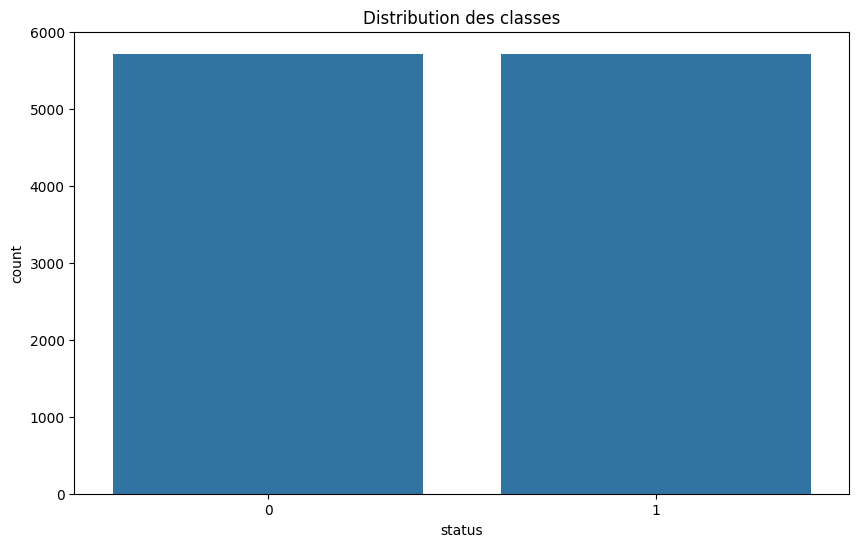

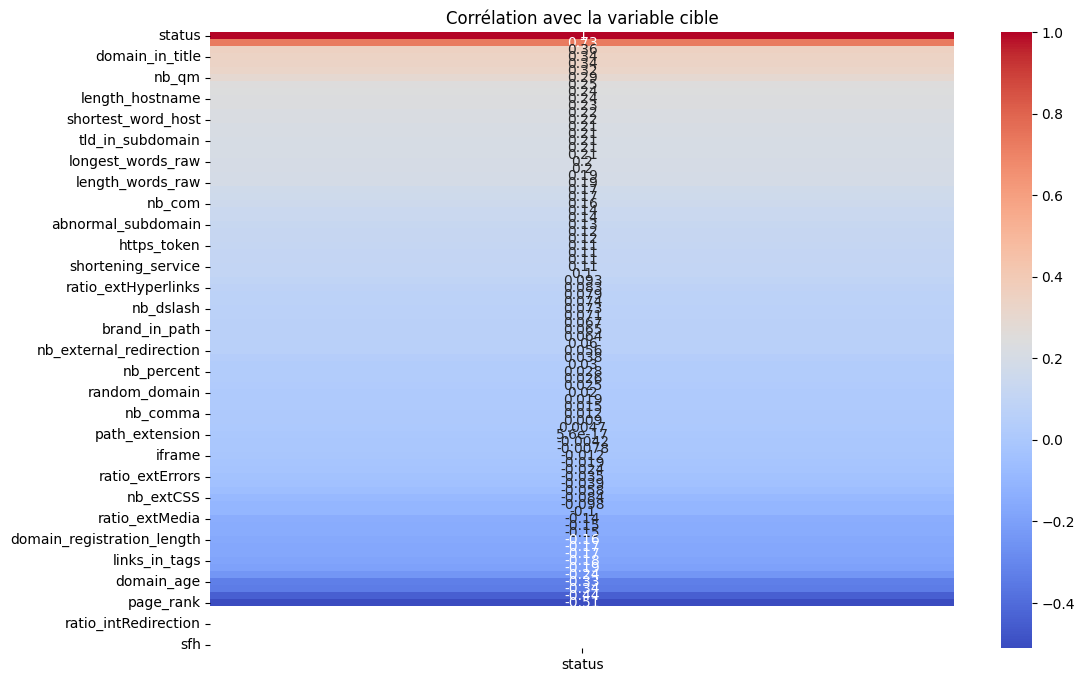

In [ ]:
# ---------------------------------------------------
# Étape 2: Analyse exploratoire (EDA)
# ---------------------------------------------------
plt.figure(figsize=(10, 6))
sns.countplot(x='status', data=df)
plt.title('Distribution des classes')
plt.show()

plt.figure(figsize=(12, 8))
sns.heatmap(df.corr()[['status']].sort_values('status', ascending=False),
            annot=True, cmap='coolwarm')
plt.title('Corrélation avec la variable cible')
plt.show()

In [ ]:
# ---------------------------------------------------
# Étape 3: Préparation des données pour le modèle
# ---------------------------------------------------
# Séparation features/target
X = df.drop(columns=['status']).values
y = df['status'].values

# Normalisation des données
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Redimensionnement pour l'entrée du modèle
X = X.reshape(X.shape[0], X.shape[1], 1)

# Split des données
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                   test_size=0.2,
                                                   random_state=42,
                                                   stratify=y)

In [ ]:
# ---------------------------------------------------
# Étape 4: Architecture parallèle CNN-LSTM
# ---------------------------------------------------
def build_parallel_model(input_shape):
    # Couche d'entrée principale
    input_layer = Input(shape=input_shape)

    # ------------------------
    # Branche CNN
    # ------------------------
    cnn = Conv1D(64, 3, activation='relu')(input_layer)
    cnn = BatchNormalization()(cnn)
    cnn = MaxPooling1D(2)(cnn)
    cnn = Dropout(0.3)(cnn)

    cnn = Conv1D(128, 3, activation='relu')(cnn)
    cnn = BatchNormalization()(cnn)
    cnn = MaxPooling1D(2)(cnn)
    cnn = Dropout(0.4)(cnn)

    cnn = Flatten()(cnn)

    # ------------------------
    # Branche LSTM
    # ------------------------
    lstm = LSTM(64, return_sequences=True)(input_layer)
    lstm = LSTM(32)(lstm)

    # ------------------------
    # Combinaison des branches
    # ------------------------
    combined = concatenate([cnn, lstm])

    # Couches Dense finales
    combined = Dense(256, activation='relu')(combined)
    combined = BatchNormalization()(combined)
    combined = Dropout(0.5)(combined)

    output = Dense(1, activation='sigmoid')(combined)

    # Création du modèle
    model = Model(inputs=input_layer, outputs=output)

    model.compile(optimizer='adam',
                 loss='binary_crossentropy',
                 metrics=['accuracy',
                         tf.keras.metrics.Precision(name='precision'),
                         tf.keras.metrics.Recall(name='recall')])
    return model

# Construction et affichage du modèle
model = build_parallel_model((X_train.shape[1], 1))
model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)  │ (None, 87, 1)          │              0 │ -                      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv1d (Conv1D)           │ (None, 85, 64)         │            256 │ input_layer[0][0]      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization       │ (None, 85, 64)         │            256 │ conv1d[0][0]           │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling1d             │ (None, 42, 64)         │              0 │ batch_normalization[0… │
│ (MaxPooling1D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dropout (Dropout)         │ (None, 42, 64)         │              0 │ max_pooling1d[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv1d_1 (Conv1D)         │ (None, 40, 128)        │         24,704 │ dropout[0][0]          │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_1     │ (None, 40, 128)        │            512 │ conv1d_1[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling1d_1           │ (None, 20, 128)        │              0 │ batch_normalization_1… │
│ (MaxPooling1D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dropout_1 (Dropout)       │ (None, 20, 128)        │              0 │ max_pooling1d_1[0][0]  │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ lstm (LSTM)               │ (None, 87, 64)         │         16,896 │ input_layer[0][0]      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ flatten (Flatten)         │ (None, 2560)           │              0 │ dropout_1[0][0]        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ lstm_1 (LSTM)             │ (None, 32)             │         12,416 │ lstm[0][0]             │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ concatenate (Concatenate) │ (None, 2592)           │              0 │ flatten[0][0],         │
│                           │                        │                │ lstm_1[0][0]           │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense (Dense)             │ (None, 256)            │        663,808 │ concatenate[0][0]      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_2     │ (None, 256)            │          1,024 │ dense[0][0]            │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dropout_2 (Dropout)       │ (None, 256)            │              0 │ batch_normalization_2… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_1 (Dense)      

 Total params: 720,129 (2.75 MB)

 Trainable params: 719,233 (2.74 MB)

 Non-trainable params: 896 (3.50 KB)

In [ ]:
# ---------------------------------------------------
# Étape 5: Entraînement avec gestion de l'overfitting
# ---------------------------------------------------
callbacks = [
    EarlyStopping(patience=10, restore_best_weights=True),
    ModelCheckpoint('best_parallel_model.h5', save_best_only=True)
]

history = model.fit(X_train, y_train,
                   epochs=100,
                   batch_size=64,
                   validation_split=0.2,
                   callbacks=callbacks,
                   class_weight={0: 1, 1: 1.2})

Epoch 1/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step - accuracy: 0.8117 - loss: 0.5544 - precision: 0.8055 - recall: 0.8226

115/115 ━━━━━━━━━━━━━━━━━━━━ 26s 157ms/step - accuracy: 0.8121 - loss: 0.5533 - precision: 0.8059 - recall: 0.8229 - val_accuracy: 0.5631 - val_loss: 0.7906 - val_precision: 0.9841 - val_recall: 0.1346
Epoch 2/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 0.8995 - loss: 0.2884 - precision: 0.8847 - recall: 0.9142

115/115 ━━━━━━━━━━━━━━━━━━━━ 26s 227ms/step - accuracy: 0.8995 - loss: 0.2883 - precision: 0.8848 - recall: 0.9142 - val_accuracy: 0.7479 - val_loss: 0.4739 - val_precision: 0.9936 - val_recall: 0.5027
Epoch 3/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 185ms/step - accuracy: 0.9169 - loss: 0.2377 - precision: 0.9057 - recall: 0.9284

115/115 ━━━━━━━━━━━━━━━━━━━━ 23s 196ms/step - accuracy: 0.9169 - loss: 0.2376 - precision: 0.9058 - recall: 0.9284 - val_accuracy: 0.9202 - val_loss: 0.2233 - val_precision: 0.9755 - val_recall: 0.8632
Epoch 4/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step - accuracy: 0.9264 - loss: 0.2137 - precision: 0.9159 - recall: 0.9361

115/115 ━━━━━━━━━━━━━━━━━━━━ 38s 171ms/step - accuracy: 0.9264 - loss: 0.2137 - precision: 0.9159 - recall: 0.9361 - val_accuracy: 0.9464 - val_loss: 0.1588 - val_precision: 0.9577 - val_recall: 0.9349
Epoch 5/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step - accuracy: 0.9243 - loss: 0.2042 - precision: 0.9127 - recall: 0.9338

...

115/115 ━━━━━━━━━━━━━━━━━━━━ 21s 157ms/step - accuracy: 0.9518 - loss: 0.1323 - precision: 0.9461 - recall: 0.9588 - val_accuracy: 0.9601 - val_loss: 0.1151 - val_precision: 0.9680 - val_recall: 0.9522
Epoch 11/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.9567 - loss: 0.1238 - precision: 0.9540 - recall: 0.9600

115/115 ━━━━━━━━━━━━━━━━━━━━ 19s 149ms/step - accuracy: 0.9567 - loss: 0.1238 - precision: 0.9539 - recall: 0.9600 - val_accuracy: 0.9677 - val_loss: 0.1047 - val_precision: 0.9778 - val_recall: 0.9577
Epoch 12/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step - accuracy: 0.9583 - loss: 0.1218 - precision: 0.9573 - recall: 0.9584

115/115 ━━━━━━━━━━━━━━━━━━━━ 18s 158ms/step - accuracy: 0.9583 - loss: 0.1219 - precision: 0.9573 - recall: 0.9584 - val_accuracy: 0.9672 - val_loss: 0.1034 - val_precision: 0.9654 - val_recall: 0.9696
Epoch 13/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 20s 150ms/step - accuracy: 0.9567 - loss: 0.1155 - precision: 0.9461 - recall: 0.9664 - val_accuracy: 0.9661 - val_loss: 0.1086 - val_precision: 0.9704 - val_recall: 0.9620
Epoch 14/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step - accuracy: 0.9647 - loss: 0.1142 - precision: 0.9651 - recall: 0.9631

115/115 ━━━━━━━━━━━━━━━━━━━━ 22s 160ms/step - accuracy: 0.9647 - loss: 0.1142 - precision: 0.9651 - recall: 0.9631 - val_accuracy: 0.9628 - val_loss: 0.1034 - val_precision: 0.9571 - val_recall: 0.9696
Epoch 15/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.9671 - loss: 0.0991 - precision: 0.9591 - recall: 0.9755

115/115 ━━━━━━━━━━━━━━━━━━━━ 19s 149ms/step - accuracy: 0.9670 - loss: 0.0992 - precision: 0.9590 - recall: 0.9754 - val_accuracy: 0.9661 - val_loss: 0.0949 - val_precision: 0.9674 - val_recall: 0.9653
Epoch 16/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 18s 159ms/step - accuracy: 0.9666 - loss: 0.0961 - precision: 0.9671 - recall: 0.9671 - val_accuracy: 0.9650 - val_loss: 0.0992 - val_precision: 0.9612 - val_recall: 0.9696
Epoch 17/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 20s 173ms/step - accuracy: 0.9607 - loss: 0.1023 - precision: 0.9521 - recall: 0.9689 - val_accuracy: 0.9688 - val_loss: 0.0995 - val_precision: 0.9726 - val_recall: 0.9653
Epoch 18/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 19s 158ms/step - accuracy: 0.9690 - loss: 0.0952 - precision: 0.9643 - recall: 0.9744 - val_accuracy: 0.9623 - val_loss: 0.1035 - val_precision: 0.9591 - val_recall: 0.9663
Epoch 19/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 19s 148ms/step - accuracy: 0.9701 - loss: 0.0899 - precision: 0.9663 - recall: 0.9742 - val_accuracy: 0.9694 - 

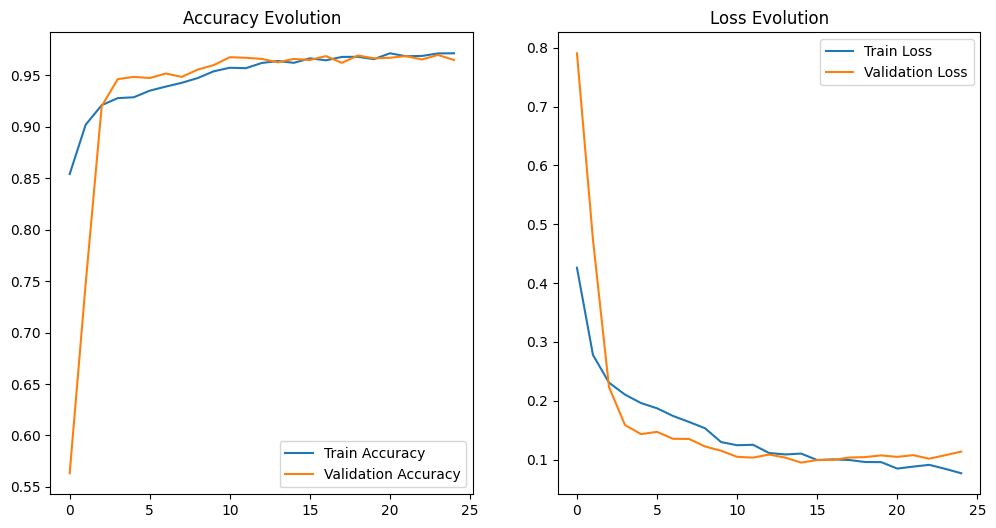

72/72 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step
              precision    recall  f1-score   support

           0       0.96      0.95      0.96      1143
           1       0.95      0.96      0.96      1143

    accuracy                           0.96      2286
   macro avg       0.96      0.96      0.96      2286
weighted avg       0.96      0.96      0.96      2286



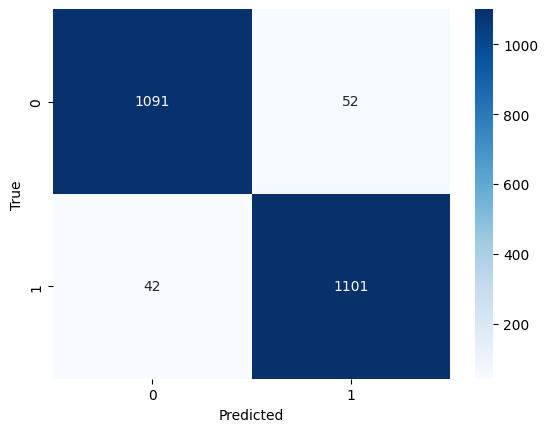

72/72 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step


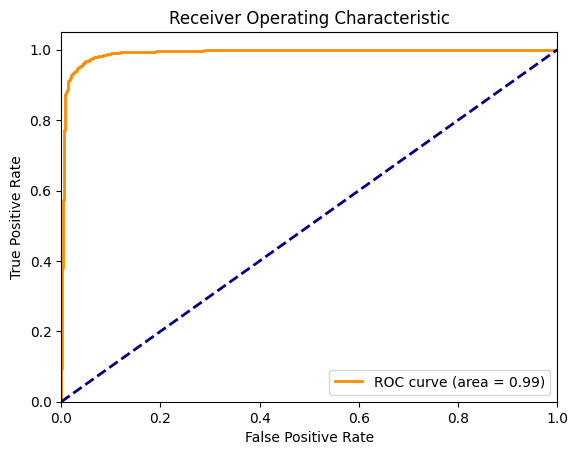

In [ ]:
# ---------------------------------------------------
# Étape 6: Évaluation du modèle
# ---------------------------------------------------
# Courbes d'apprentissage
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy Evolution')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss Evolution')
plt.legend()
plt.show()

# Évaluation finale
y_pred = (model.predict(X_test) > 0.5).astype(int)
print(classification_report(y_test, y_pred))

# Matrice de confusion
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# Courbe ROC
fpr, tpr, thresholds = roc_curve(y_test, model.predict(X_test))
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

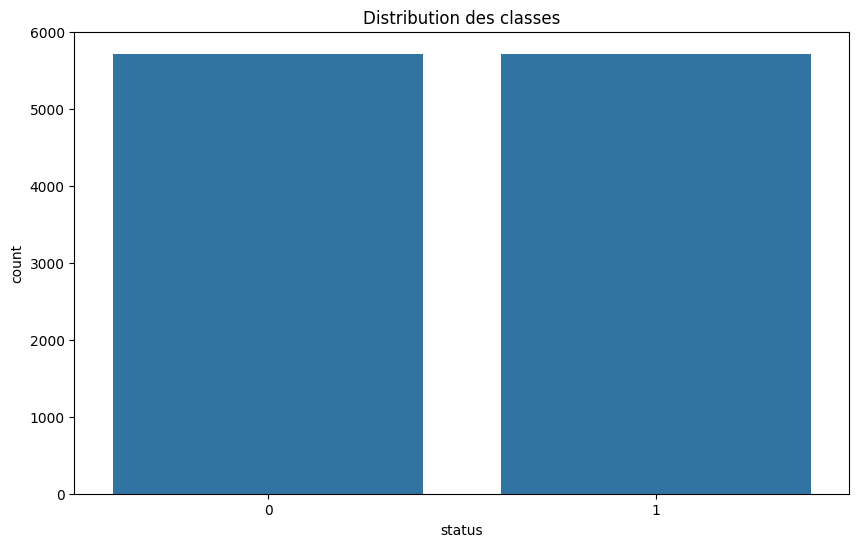

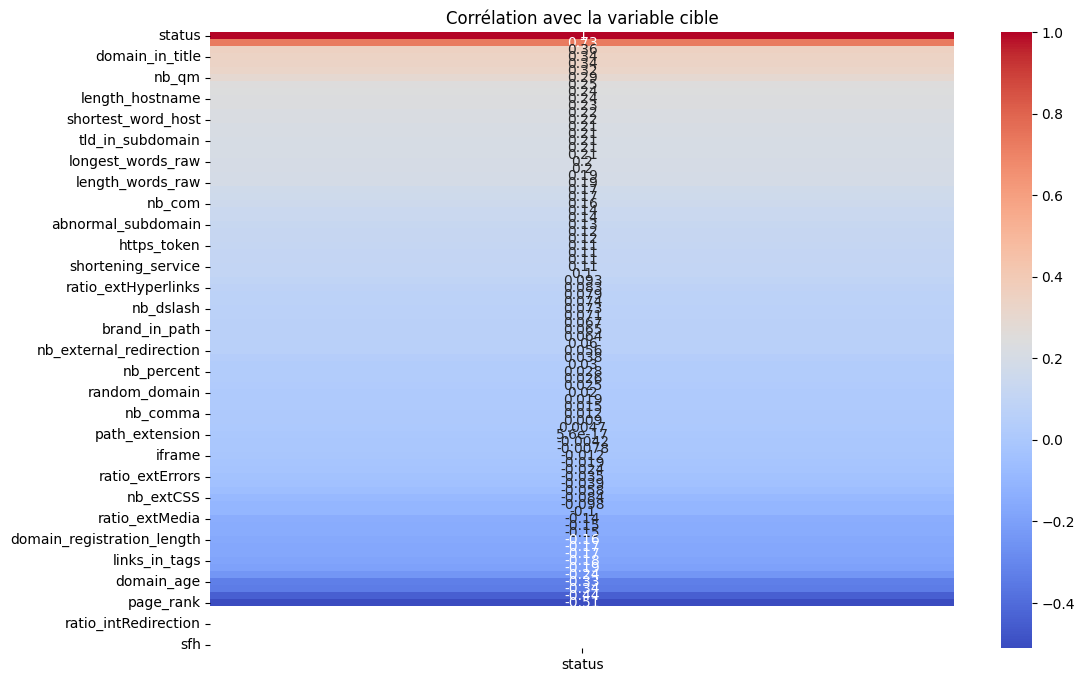

Nombre de points supprimés : 115
Distribution après équilibrage : [5709 5709]

Entraînement du modèle MLP 1/100...


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Modèle 1 terminé.

Entraînement du modèle MLP 2/100...


Modèle 2 terminé.

Entraînement du modèle MLP 3/100...
Modèle 3 terminé.

Entraînement du modèle MLP 4/100...
Modèle 4 terminé.

Entraînement du modèle MLP 5/100...
Modèle 5 terminé.

Entraînement du modèle MLP 6/100...
Modèle 6 terminé.

Entraînement du modèle MLP 7/100...
Modèle 7 terminé.

Entraînement du modèle MLP 8/100...
Modèle 8 terminé.

Entraînement du modèle MLP 9/100...
Modèle 9 terminé.

Entraînement du modèle MLP 10/100...
Modèle 10 terminé.

Entraînement du modèle MLP 11/100...
Modèle 11 terminé.

Entraînement du modèle MLP 12/100...
Modèle 12 terminé.

Entraînement du modèle MLP 13/100...
Modèle 13 terminé.

Entraînement du modèle MLP 14/100...
Modèle 14 terminé.

Entraînement du modèle MLP 15/100...
Modèle 15 terminé.

Entraînement du modèle MLP 16/100...
Modèle 16 terminé.

Entraînement du modèle MLP 17/100...
Modèle 17 terminé.

Entraînement du modèle MLP 18/100...


Modèle 18 terminé.

Entraînement du modèle MLP 19/100...
Modèle 19 terminé.

Entraînement du modèle MLP 20/100...
Modèle 20 terminé.

Entraînement du modèle MLP 21/100...
Modèle 21 terminé.

Entraînement du modèle MLP 22/100...
Modèle 22 terminé.

Entraînement du modèle MLP 23/100...
Modèle 23 terminé.

Entraînement du modèle MLP 24/100...


Modèle 24 terminé.

Entraînement du modèle MLP 25/100...
Modèle 25 terminé.

Entraînement du modèle MLP 26/100...
Modèle 26 terminé.

Entraînement du modèle MLP 27/100...
Modèle 27 terminé.

Entraînement du modèle MLP 28/100...
Modèle 28 terminé.

Entraînement du modèle MLP 29/100...
Modèle 29 terminé.

Entraînement du modèle MLP 30/100...
Modèle 30 terminé.

Entraînement du modèle MLP 31/100...
Modèle 31 terminé.

Entraînement du modèle MLP 32/100...
Modèle 32 terminé.

Entraînement du modèle MLP 33/100...
Modèle 33 terminé.

Entraînement du modèle MLP 34/100...
Modèle 34 terminé.

Entraînement du modèle MLP 35/100...
Modèle 35 terminé.

Entraînement du modèle MLP 36/100...
Modèle 36 terminé.

Entraînement du modèle MLP 37/100...
Modèle 37 terminé.

Entraînement du modèle MLP 38/100...
Modèle 38 terminé.

Entraînement du modèle MLP 39/100...
Modèle 39 terminé.

Entraînement du modèle MLP 40/100...
Modèle 40 terminé.

Entraînement du modèle MLP 41/100...


Modèle 41 terminé.

Entraînement du modèle MLP 42/100...
Modèle 42 terminé.

Entraînement du modèle MLP 43/100...
Modèle 43 terminé.

Entraînement du modèle MLP 44/100...
Modèle 44 terminé.

Entraînement du modèle MLP 45/100...
Modèle 45 terminé.

Entraînement du modèle MLP 46/100...
Modèle 46 terminé.

Entraînement du modèle MLP 47/100...
Modèle 47 terminé.

Entraînement du modèle MLP 48/100...
Modèle 48 terminé.

Entraînement du modèle MLP 49/100...
Modèle 49 terminé.

Entraînement du modèle MLP 50/100...
Modèle 50 terminé.

Entraînement du modèle MLP 51/100...
Modèle 51 terminé.

Entraînement du modèle MLP 52/100...
Modèle 52 terminé.

Entraînement du modèle MLP 53/100...
Modèle 53 terminé.

Entraînement du modèle MLP 54/100...
Modèle 54 terminé.

Entraînement du modèle MLP 55/100...
Modèle 55 terminé.

Entraînement du modèle MLP 56/100...
Modèle 56 terminé.

Entraînement du modèle MLP 57/100...
Modèle 57 terminé.

Entraînement du modèle MLP 58/100...
Modèle 58 terminé.

Entraînemen

Modèle 89 terminé.

Entraînement du modèle MLP 90/100...
Modèle 90 terminé.

Entraînement du modèle MLP 91/100...
Modèle 91 terminé.

Entraînement du modèle MLP 92/100...
Modèle 92 terminé.

Entraînement du modèle MLP 93/100...
Modèle 93 terminé.

Entraînement du modèle MLP 94/100...
Modèle 94 terminé.

Entraînement du modèle MLP 95/100...
Modèle 95 terminé.

Entraînement du modèle MLP 96/100...
Modèle 96 terminé.

Entraînement du modèle MLP 97/100...
Modèle 97 terminé.

Entraînement du modèle MLP 98/100...
Modèle 98 terminé.

Entraînement du modèle MLP 99/100...
Modèle 99 terminé.

Entraînement du modèle MLP 100/100...
Modèle 100 terminé.
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
7

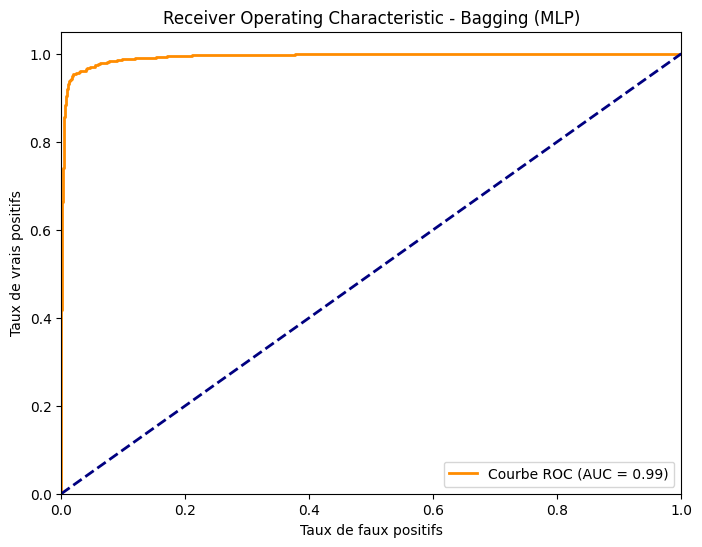

In [ ]:
# Importation des librairies nécessaires
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Prétraitement et Split
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_curve, auc

# Modèles deep learning avec Keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, BatchNormalization, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import tensorflow as tf

# Modèles scikit-learn et XGBoost
from sklearn.ensemble import IsolationForest
import xgboost as xgb

# Pour équilibrer la dataset
from imblearn.over_sampling import RandomOverSampler

# Méta-modèle (pour l'exemple précédent, ici nous utilisons le bagging pour un MLP)
from sklearn.linear_model import LogisticRegression

# Chargement du dataset
df = pd.read_csv("dataset_phishing.csv")

# Préparation des données
df = df.drop(columns=['url'])  # Suppression de la colonne non pertinente
df['status'] = df['status'].map({'legitimate': 0, 'phishing': 1})  # Encodage de la variable cible

# Suppression des lignes avec des NaN dans 'status'
df.dropna(subset=['status'], inplace=True)

# Visualisation exploratoire (optionnel)
plt.figure(figsize=(10, 6))
sns.countplot(x='status', data=df)
plt.title('Distribution des classes')
plt.show()

plt.figure(figsize=(12, 8))
sns.heatmap(df.corr()[['status']].sort_values('status', ascending=False),
            annot=True, cmap='coolwarm')
plt.title('Corrélation avec la variable cible')
plt.show()

# Séparation des features et de la target
X = df.drop(columns=['status']).values
y = df['status'].values

# Normalisation des features
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Suppression des anomalies avec IsolationForest
iso = IsolationForest(contamination=0.01, random_state=42)
pred_anomalies = iso.fit_predict(X)
mask = pred_anomalies != -1  # Conserve les échantillons jugés normaux
nombre_supprimes = len(X) - np.sum(mask)
print(f"Nombre de points supprimés : {nombre_supprimes}")

X = X[mask]
y = y[mask]

# Équilibrage de la dataset avec sur-échantillonnage
ros = RandomOverSampler(random_state=42)
X, y = ros.fit_resample(X, y)
print("Distribution après équilibrage :", np.bincount(y))

# Split train/test
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y)

# -------------------------------------------------------
# Définition du modèle de base (MLP)
# -------------------------------------------------------
def build_mlp(input_shape):
    model = Sequential([
        Dense(128, activation='relu', input_shape=(input_shape,)),
        BatchNormalization(),
        Dropout(0.3),
        Dense(64, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(32, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()])
    return model

# -------------------------------------------------------
# Mise en place du Bagging pour le modèle MLP
# -------------------------------------------------------
import random

n_estimators = 100         # Nombre de modèles dans l'ensemble
epochs = 100
batch_size = 64

bagging_models = []      # Liste pour stocker les modèles
callbacks = [
    EarlyStopping(patience=10, restore_best_weights=True),
    ModelCheckpoint('best_model.h5', save_best_only=True)
]

# Entraînement de chaque modèle sur un bootstrap (échantillonnage avec remplacement)
for i in range(n_estimators):
    print(f"\nEntraînement du modèle MLP {i+1}/{n_estimators}...")
    # Création d'un échantillon bootstrap
    indices = np.random.choice(np.arange(len(X_train)), size=len(X_train), replace=True)
    X_train_boot = X_train[indices]
    y_train_boot = y_train[indices]

    # Construction et entraînement du modèle
    model = build_mlp(X_train.shape[1])
    model.fit(X_train_boot, y_train_boot,
              epochs=epochs,
              batch_size=batch_size,
              validation_split=0.2,
              callbacks=callbacks,
              class_weight={0: 1, 1: 1.2},
              verbose=0)
    bagging_models.append(model)
    print(f"Modèle {i+1} terminé.")

# -------------------------------------------------------
# Agrégation des prédictions (vote majoritaire via moyenne des probabilités)
# -------------------------------------------------------
# Prédiction pour chaque modèle sur l'ensemble de test
predictions = []
for model in bagging_models:
    pred = model.predict(X_test)
    predictions.append(pred)

# Convertir la liste en tableau et calculer la moyenne
predictions = np.array(predictions)  # forme: (n_estimators, n_samples, 1)
avg_predictions = np.mean(predictions, axis=0)

# Appliquer un seuil de 0.5 pour obtenir la classe finale
y_pred_bagging = (avg_predictions >= 0.5).astype(int).ravel()

# Évaluation des performances
print("\n--- Rapport de classification (Bagging - MLP) ---")
print(classification_report(y_test, y_pred_bagging))

# Calcul de la courbe ROC pour le bagging
proba_bagging = avg_predictions.ravel()
fpr, tpr, thresholds = roc_curve(y_test, proba_bagging)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Courbe ROC (AUC = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taux de faux positifs')
plt.ylabel('Taux de vrais positifs')
plt.title('Receiver Operating Characteristic - Bagging (MLP)')
plt.legend(loc="lower right")
plt.show()


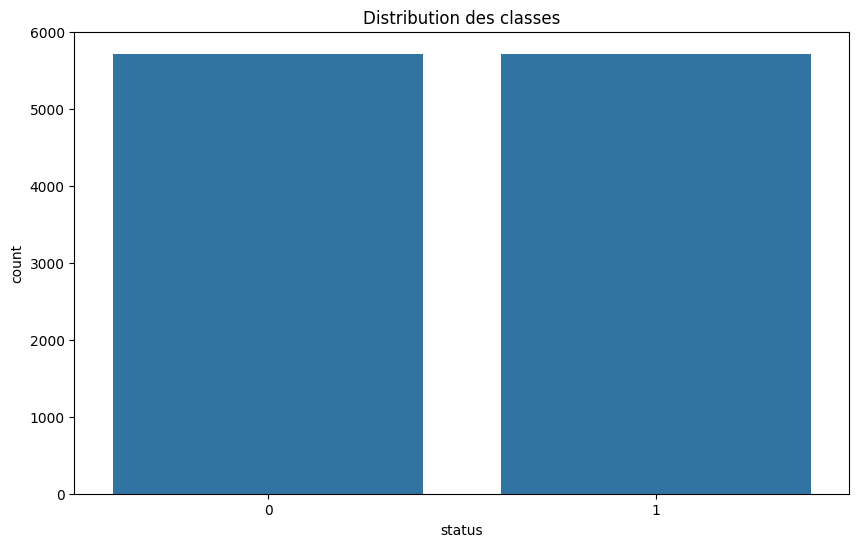

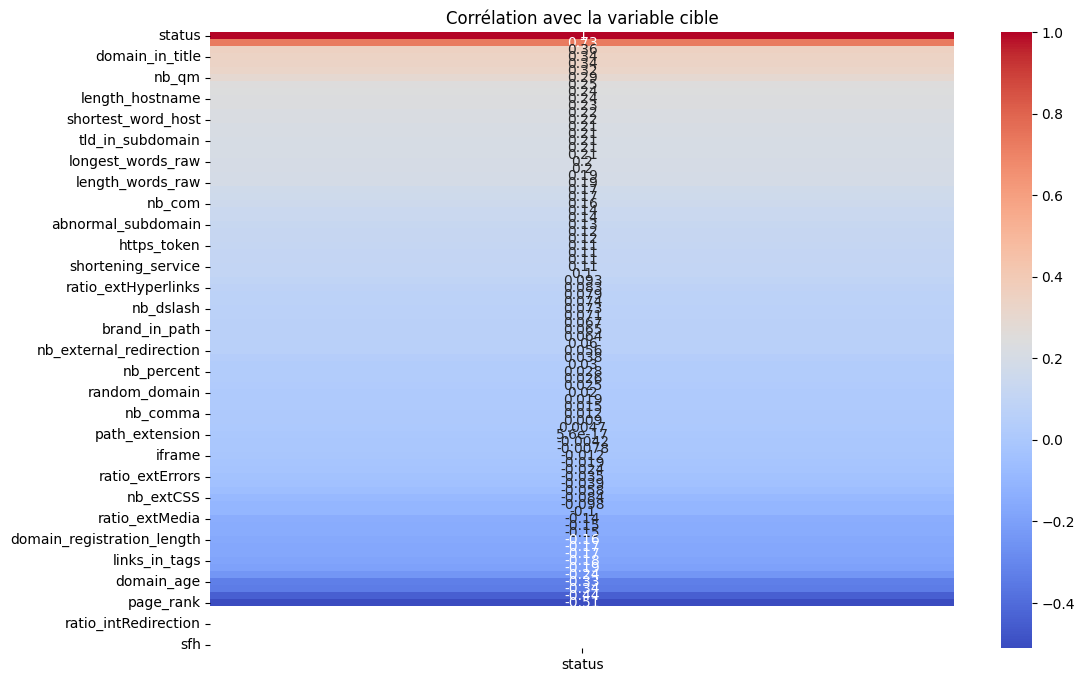

Nombre de points supprimés : 115
Distribution après équilibrage : [5709 5709]

Entraînement du modèle MLP 1/8...


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Modèle 1 terminé.

Entraînement du modèle MLP 2/8...
Modèle 2 terminé.

Entraînement du modèle MLP 3/8...
Modèle 3 terminé.

Entraînement du modèle MLP 4/8...
Modèle 4 terminé.

Entraînement du modèle MLP 5/8...


Modèle 5 terminé.

Entraînement du modèle MLP 6/8...
Modèle 6 terminé.

Entraînement du modèle MLP 7/8...
Modèle 7 terminé.

Entraînement du modèle MLP 8/8...
Modèle 8 terminé.
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

--- Rapport de classification (Bagging - MLP) ---
              precision    recall  f1-score   support

           0       0.96      0.97      0.97      1142
           1       0.97      0.96      0.97      1142

    accuracy                           0.97      2284
   macro avg       0.97      0.97      0.97      2284
weighted avg       0.97      0.97      0.97      2284



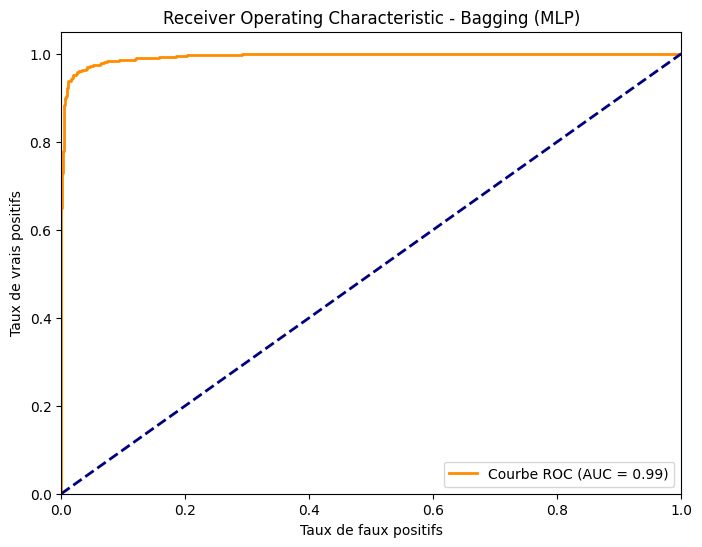

In [ ]:
# Importation des librairies nécessaires
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Prétraitement et Split
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_curve, auc

# Modèles deep learning avec Keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, BatchNormalization, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import tensorflow as tf

# Modèles scikit-learn et XGBoost
from sklearn.ensemble import IsolationForest
import xgboost as xgb

# Pour équilibrer la dataset
from imblearn.over_sampling import RandomOverSampler

# Méta-modèle (pour l'exemple précédent, ici nous utilisons le bagging pour un MLP)
from sklearn.linear_model import LogisticRegression

# Chargement du dataset
df = pd.read_csv("dataset_phishing.csv")

# Préparation des données
df = df.drop(columns=['url'])  # Suppression de la colonne non pertinente
df['status'] = df['status'].map({'legitimate': 0, 'phishing': 1})  # Encodage de la variable cible

# Suppression des lignes avec des NaN dans 'status'
df.dropna(subset=['status'], inplace=True)

# Visualisation exploratoire (optionnel)
plt.figure(figsize=(10, 6))
sns.countplot(x='status', data=df)
plt.title('Distribution des classes')
plt.show()

plt.figure(figsize=(12, 8))
sns.heatmap(df.corr()[['status']].sort_values('status', ascending=False),
            annot=True, cmap='coolwarm')
plt.title('Corrélation avec la variable cible')
plt.show()

# Séparation des features et de la target
X = df.drop(columns=['status']).values
y = df['status'].values

# Normalisation des features
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Suppression des anomalies avec IsolationForest
iso = IsolationForest(contamination=0.01, random_state=42)
pred_anomalies = iso.fit_predict(X)
mask = pred_anomalies != -1  # Conserve les échantillons jugés normaux
nombre_supprimes = len(X) - np.sum(mask)
print(f"Nombre de points supprimés : {nombre_supprimes}")

X = X[mask]
y = y[mask]

# Équilibrage de la dataset avec sur-échantillonnage
ros = RandomOverSampler(random_state=42)
X, y = ros.fit_resample(X, y)
print("Distribution après équilibrage :", np.bincount(y))

# Split train/test
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y)

# -------------------------------------------------------
# Définition du modèle de base (MLP)
# -------------------------------------------------------
def build_mlp(input_shape):
    model = Sequential([
        Dense(128, activation='relu', input_shape=(input_shape,)),
        BatchNormalization(),
        Dropout(0.3),
        Dense(64, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(32, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()])
    return model

# -------------------------------------------------------
# Mise en place du Bagging pour le modèle MLP
# -------------------------------------------------------
import random

n_estimators = 8         # Nombre de modèles dans l'ensemble
epochs = 100
batch_size = 64

bagging_models = []      # Liste pour stocker les modèles
callbacks = [
    EarlyStopping(patience=10, restore_best_weights=True),
    ModelCheckpoint('best_model.h5', save_best_only=True)
]

# Entraînement de chaque modèle sur un bootstrap (échantillonnage avec remplacement)
for i in range(n_estimators):
    print(f"\nEntraînement du modèle MLP {i+1}/{n_estimators}...")
    # Création d'un échantillon bootstrap
    indices = np.random.choice(np.arange(len(X_train)), size=len(X_train), replace=True)
    X_train_boot = X_train[indices]
    y_train_boot = y_train[indices]

    # Construction et entraînement du modèle
    model = build_mlp(X_train.shape[1])
    model.fit(X_train_boot, y_train_boot,
              epochs=epochs,
              batch_size=batch_size,
              validation_split=0.2,
              callbacks=callbacks,
              class_weight={0: 1, 1: 1.2},
              verbose=0)
    bagging_models.append(model)
    print(f"Modèle {i+1} terminé.")

# -------------------------------------------------------
# Agrégation des prédictions (vote majoritaire via moyenne des probabilités)
# -------------------------------------------------------
# Prédiction pour chaque modèle sur l'ensemble de test
predictions = []
for model in bagging_models:
    pred = model.predict(X_test)
    predictions.append(pred)

# Convertir la liste en tableau et calculer la moyenne
predictions = np.array(predictions)  # forme: (n_estimators, n_samples, 1)
avg_predictions = np.mean(predictions, axis=0)

# Appliquer un seuil de 0.5 pour obtenir la classe finale
y_pred_bagging = (avg_predictions >= 0.5).astype(int).ravel()

# Évaluation des performances
print("\n--- Rapport de classification (Bagging - MLP) ---")
print(classification_report(y_test, y_pred_bagging))

# Calcul de la courbe ROC pour le bagging
proba_bagging = avg_predictions.ravel()
fpr, tpr, thresholds = roc_curve(y_test, proba_bagging)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Courbe ROC (AUC = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taux de faux positifs')
plt.ylabel('Taux de vrais positifs')
plt.title('Receiver Operating Characteristic - Bagging (MLP)')
plt.legend(loc="lower right")
plt.show()


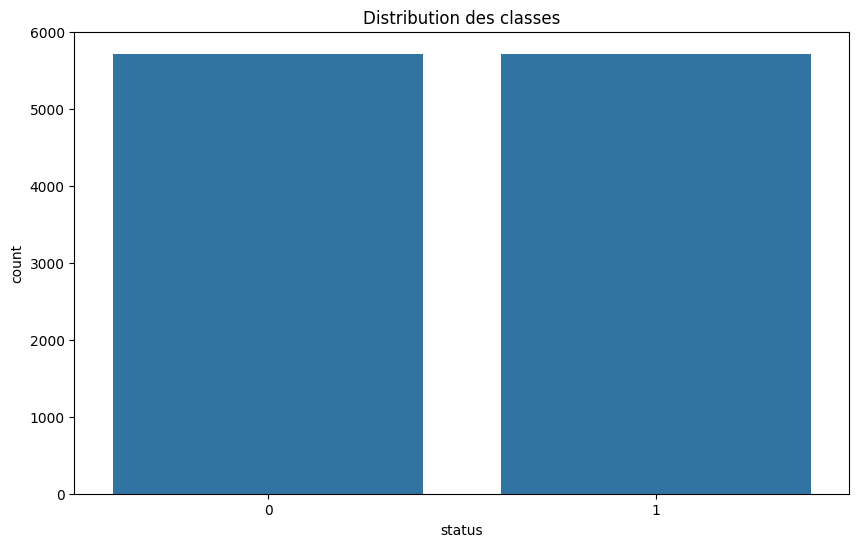

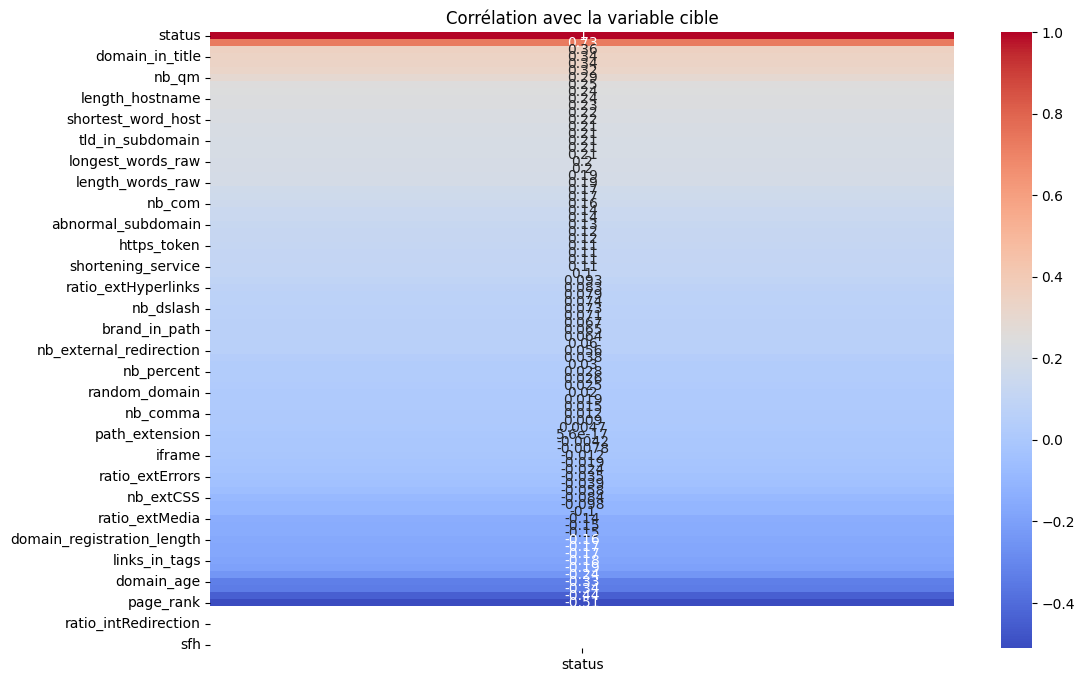

Nombre de points supprimés : 115
Distribution après équilibrage : [5709 5709]

Entraînement du modèle MLP 1/9...


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Modèle 1 terminé.

Entraînement du modèle MLP 2/9...
Modèle 2 terminé.

Entraînement du modèle MLP 3/9...


Modèle 3 terminé.

Entraînement du modèle MLP 4/9...


Modèle 4 terminé.

Entraînement du modèle MLP 5/9...


Modèle 5 terminé.

Entraînement du modèle MLP 6/9...
Modèle 6 terminé.

Entraînement du modèle MLP 7/9...
Modèle 7 terminé.

Entraînement du modèle MLP 8/9...
Modèle 8 terminé.

Entraînement du modèle MLP 9/9...
Modèle 9 terminé.
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

--- Rapport de classification (Bagging - MLP) ---
              precision    recall  f1-score   support

           0       0.96      0.97      0.96      1142
           1       0.97      0.96      0.96      1142

    accuracy                           0.96      2284
   macro avg       0.96      0.96      0.96      2284
weighted avg       0.96      0.96      0.96      2284



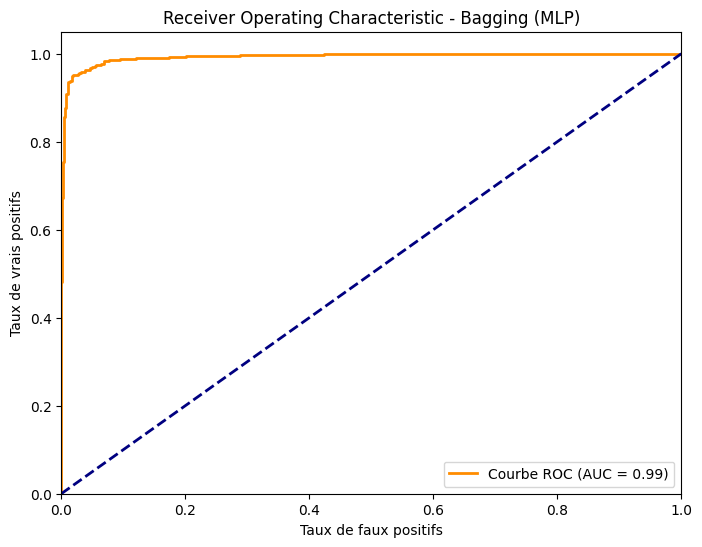

In [ ]:
# Importation des librairies nécessaires
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Prétraitement et Split
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_curve, auc

# Modèles deep learning avec Keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, BatchNormalization, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import tensorflow as tf

# Modèles scikit-learn et XGBoost
from sklearn.ensemble import IsolationForest
import xgboost as xgb

# Pour équilibrer la dataset
from imblearn.over_sampling import RandomOverSampler

# Méta-modèle (pour l'exemple précédent, ici nous utilisons le bagging pour un MLP)
from sklearn.linear_model import LogisticRegression

# Chargement du dataset
df = pd.read_csv("dataset_phishing.csv")

# Préparation des données
df = df.drop(columns=['url'])  # Suppression de la colonne non pertinente
df['status'] = df['status'].map({'legitimate': 0, 'phishing': 1})  # Encodage de la variable cible

# Suppression des lignes avec des NaN dans 'status'
df.dropna(subset=['status'], inplace=True)

# Visualisation exploratoire (optionnel)
plt.figure(figsize=(10, 6))
sns.countplot(x='status', data=df)
plt.title('Distribution des classes')
plt.show()

plt.figure(figsize=(12, 8))
sns.heatmap(df.corr()[['status']].sort_values('status', ascending=False),
            annot=True, cmap='coolwarm')
plt.title('Corrélation avec la variable cible')
plt.show()

# Séparation des features et de la target
X = df.drop(columns=['status']).values
y = df['status'].values

# Normalisation des features
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Suppression des anomalies avec IsolationForest
iso = IsolationForest(contamination=0.01, random_state=42)
pred_anomalies = iso.fit_predict(X)
mask = pred_anomalies != -1  # Conserve les échantillons jugés normaux
nombre_supprimes = len(X) - np.sum(mask)
print(f"Nombre de points supprimés : {nombre_supprimes}")

X = X[mask]
y = y[mask]

# Équilibrage de la dataset avec sur-échantillonnage
ros = RandomOverSampler(random_state=42)
X, y = ros.fit_resample(X, y)
print("Distribution après équilibrage :", np.bincount(y))

# Split train/test
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y)

# -------------------------------------------------------
# Définition du modèle de base (MLP)
# -------------------------------------------------------
def build_mlp(input_shape):
    model = Sequential([
        Dense(128, activation='relu', input_shape=(input_shape,)),
        BatchNormalization(),
        Dropout(0.3),
        Dense(64, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(32, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()])
    return model

# -------------------------------------------------------
# Mise en place du Bagging pour le modèle MLP
# -------------------------------------------------------
import random

n_estimators = 9         # Nombre de modèles dans l'ensemble
epochs = 100
batch_size = 64

bagging_models = []      # Liste pour stocker les modèles
callbacks = [
    EarlyStopping(patience=10, restore_best_weights=True),
    ModelCheckpoint('best_model.h5', save_best_only=True)
]

# Entraînement de chaque modèle sur un bootstrap (échantillonnage avec remplacement)
for i in range(n_estimators):
    print(f"\nEntraînement du modèle MLP {i+1}/{n_estimators}...")
    # Création d'un échantillon bootstrap
    indices = np.random.choice(np.arange(len(X_train)), size=len(X_train), replace=True)
    X_train_boot = X_train[indices]
    y_train_boot = y_train[indices]

    # Construction et entraînement du modèle
    model = build_mlp(X_train.shape[1])
    model.fit(X_train_boot, y_train_boot,
              epochs=epochs,
              batch_size=batch_size,
              validation_split=0.2,
              callbacks=callbacks,
              class_weight={0: 1, 1: 1.2},
              verbose=0)
    bagging_models.append(model)
    print(f"Modèle {i+1} terminé.")

# -------------------------------------------------------
# Agrégation des prédictions (vote majoritaire via moyenne des probabilités)
# -------------------------------------------------------
# Prédiction pour chaque modèle sur l'ensemble de test
predictions = []
for model in bagging_models:
    pred = model.predict(X_test)
    predictions.append(pred)

# Convertir la liste en tableau et calculer la moyenne
predictions = np.array(predictions)  # forme: (n_estimators, n_samples, 1)
avg_predictions = np.mean(predictions, axis=0)

# Appliquer un seuil de 0.5 pour obtenir la classe finale
y_pred_bagging = (avg_predictions >= 0.5).astype(int).ravel()

# Évaluation des performances
print("\n--- Rapport de classification (Bagging - MLP) ---")
print(classification_report(y_test, y_pred_bagging))

# Calcul de la courbe ROC pour le bagging
proba_bagging = avg_predictions.ravel()
fpr, tpr, thresholds = roc_curve(y_test, proba_bagging)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Courbe ROC (AUC = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taux de faux positifs')
plt.ylabel('Taux de vrais positifs')
plt.title('Receiver Operating Characteristic - Bagging (MLP)')
plt.legend(loc="lower right")
plt.show()
